# Scan parameters: what changes the splat

How the scan pipeline's settings change the result on one real phone clip, `data/raw/setup_01/bowl_1angle.mp4`: a white bowl on a wooden floor, one 25 s lap at roughly constant height.

- **Modules:** `hurobo.scan` (`SfmOptions`, `SfmReconstructor`, `SplatTrainer`, `orbit_coverage_deg`), `hurobo.scan_sweep` (`ScanSweep`, `sweep_table`), `hurobo.utils.viewer` (`sweep_figure`, `sfm_figure`)
- **Data:** real clip, not committed. This notebook only *reads* the stored sweep in `data/scans/sweeps/bowl_1angle/`. To redo it (about 30 min with a GPU):
  `uv run python scripts/14_scan_param_sweep.py data/raw/setup_01/bowl_1angle.mp4 --name bowl_1angle`
- **Setup:** one run per config, one seed, 7000 training iterations unless stated, every 10th registered keyframe withheld and used to score the splat. The splats are not cropped to the bowl.

In [1]:
from hurobo.utils.notebook import setup_notebook

ROOT = setup_notebook()  # chdir to the repo root and set MUJOCO_GL=egl

## The configs
`colmap_defaults` is what `scripts/09_scan_object.py` does today. Each following row changes one thing, until `low_threshold_exhaustive` which combines the two SfM changes, and then two variations of that.

In [2]:
from hurobo.scan_sweep import ScanSweep, sweep_table

results = ScanSweep.load(ROOT / "data/scans/sweeps/bowl_1angle")
sweep_table(results).set_index("config").T

config,colmap_defaults,low_sift_threshold,exhaustive_matching,low_threshold_exhaustive,sparse_keyframes_40,train_30k
matching,sequential,sequential,exhaustive,exhaustive,exhaustive,exhaustive
SIFT threshold,default,0.002,default,0.002,0.002,0.002
frames,120,120,120,120,40,120
spacing (s),0.19,0.19,0.19,0.19,0.58,0.19
iterations,7000,7000,7000,7000,7000,30000
registered,39/120,120/120,53/120,120/120,40/40,120/120
registered %,32,100,44,100,100,100
orbit covered (deg),180,349,214,349,142,349
models,3,1,2,1,1,1
SfM points,2867,16702,3590,23187,2599,23187


## Registration, coverage and PSNR
Read the top two panels before the PSNR. PSNR is measured only on keyframes that registered, so a config that reconstructs a short arc is scored on easy neighbouring views: `colmap_defaults` has the *highest* held-out PSNR of the sweep while using 39 of 120 frames split over three disconnected models. Orbit coverage is approximate for fragments (see `orbit_coverage_deg`).

In [3]:
from hurobo.utils.viewer import sweep_figure

sweep_figure(results, title="bowl_1angle: scan parameter sweep").show()

## The cameras COLMAP recovered
Same clip, same keyframes. Left: COLMAP's defaults reconstruct a fragment of the lap (the largest of three disconnected models). Right: with a lower SIFT contrast threshold every keyframe registers in one model and the cameras close the loop. Points are subsampled.

In [4]:
from hurobo.utils.viewer import sweep_cameras_figure

by_name = {r.config.name: r for r in results}
sweep_cameras_figure(by_name["colmap_defaults"], title="colmap_defaults", every_nth_point=4).show()
sweep_cameras_figure(by_name["low_sift_threshold"], title="low_sift_threshold", every_nth_point=4).show()

## Held-out views: photo (left) vs splat (right)
Four views each config never trained on. These are neighbours of training views along the same path, so this is interpolation along the lap, not novel viewpoints.

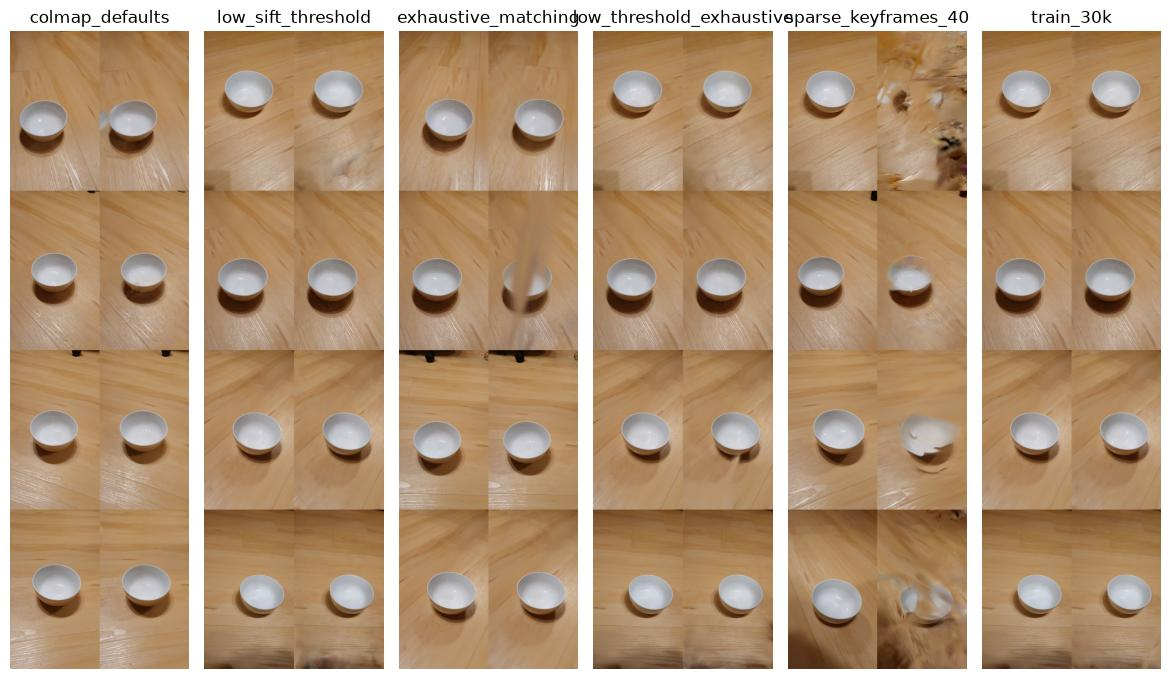

In [5]:
import matplotlib.pyplot as plt
from matplotlib_inline.backend_inline import set_matplotlib_formats

from hurobo.utils.plotting import plot_image_row

set_matplotlib_formats("jpeg")  # photos as JPEG keep the stored notebook small
plot_image_row({r.config.name: plt.imread(r.preview_path) for r in results}, height_in=7)

## The splats in 3D
Each splat rasterised with gsplat from 12 cameras orbiting its centre (full Gaussians, not just centres). Drag the slider to orbit. The splats are uncropped, so the floor and everything COLMAP triangulated around the bowl is in the view; for `colmap_defaults` that is only the fragment of the lap it registered.

In [6]:
from hurobo.splat import render_splat_orbit
from hurobo.utils.viewer import orbit_figure

for name in ["colmap_defaults", "low_threshold_exhaustive"]:
    views = render_splat_orbit(by_name[name].ply_path, num_views=12, image_size=384)
    orbit_figure(views, title=f"Rendered splat: {name}").show()

## What this shows (and what it does not)

1. **On this clip the SIFT contrast threshold is what decides registration.** COLMAP's default (0.0067) found ~500 features per frame on the smooth bowl and low-contrast floor and registered 39/120 frames in three models. Lowering it to 0.002 (with a looser ratio test of 0.9) registered 120/120 in one model with 6x the sparse points.
2. **Exhaustive matching did not help once the threshold was lowered.** With default thresholds it reached only 53/120; with the lower threshold sequential and exhaustive both give 120/120, but exhaustive SfM took 376 s against 70 s. That is specific to this clip: in a separate scratch run on the harder 3-angle clip, sequential matching with the lower threshold stopped at 74-79/120 and exhaustive was needed.
3. **PSNR alone rewards the broken scan.** `colmap_defaults` scores 33.1 dB held-out, above every fixed config (31.6-32.0 dB), because its test views lie inside a ~180 degree fragment. Check registered fraction and orbit coverage first.
4. **More training buys memorisation, not unseen-view quality.** 30k iterations vs 7k: training PSNR +2.4 dB, held-out +0.4 dB, 4.2x the Gaussians (713k vs 168k) and 5.6x the time. The train-to-held-out gap grows from 1.9 to 3.9 dB.
5. **Sparser keyframes hurt a lot, and the held-out strip shows why PSNR is not the whole story.** 40 frames (one per 0.58 s) registered 40/40 but with 2.6k points, 1.05 px reprojection error and 21.3 dB held-out, about 10 dB below the 0.19 s spacing; its renders are visibly torn and full of floaters. In the other direction, `exhaustive_matching` scores 32.4 dB yet has a floater streak across the bowl in its second held-out view.

**Limits.** One clip, one run per config, one seed: differences of a few tenths of a dB (for example 31.6 vs 32.0) cannot be ranked. Held-out sets are small (12 views for the 120-frame configs, 4 for the others), so the 40-frame number is especially noisy; a different scratch run that strided 40 of the already-registered frames scored 27.4 dB, so the size of that drop depends on how the frames are chosen, though its direction did not change. Held-out views neighbour training views along the same lap, so none of this measures novel viewpoints, and the PSNR is dominated by floor pixels rather than the bowl.